# vLLM Serving Benchmark: Prefix Caching × Concurrency

**Question:** how much does vLLM's prefix caching help, on which workload, as concurrency rises?

- 2 configs: prefix caching **off** vs **on**
- 2 workloads: `chat` (short unique prompts) vs `shared_prefix` (~1.6k-token shared document + unique question, like RAG or a long system prompt)
- 4 load levels: concurrency 1, 4, 16, 64

Metrics: time-to-first-token (TTFT) p50/p99, inter-token latency (ITL) p50/p99, output tokens/sec, server startup time, and estimated $ per 1M output tokens at a cloud T4 list price.

**Run:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all.

In [1]:
# 1. Install vLLM matched to this machine's GPU driver.
#    Newest vLLM needs a CUDA 13 driver; older Colab drivers get a pinned CUDA 12 build.
import re, subprocess
smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout
print(smi)
driver_cuda = float(re.search(r"CUDA Version: ([\d.]+)", smi).group(1))
VLLM_PKG = "vllm" if driver_cuda >= 13.0 else "vllm==0.9.2"
print(f"Driver supports CUDA {driver_cuda} -> installing {VLLM_PKG}")
!pip install -q {VLLM_PKG} httpx matplotlib

Wed Oct 14 16:25:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 2. Config
import json, time, asyncio, subprocess
from importlib.metadata import version
import httpx

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
GPU = "T4 (Colab)"
REF_PRICE_PER_SEC = 0.000164  # Modal T4 list price (modal.com/pricing, checked Oct 2026), for $/token estimates
CONCURRENCY = [1, 4, 16, 64]
MAX_TOKENS = 128
PORT = 8000
VLLM_VERSION = version("vllm")
print("vLLM", VLLM_VERSION)

vLLM 0.31.0


In [3]:
# 3. Workloads
def shared_doc() -> str:
    para = (
        "Section {i}. The logistics platform tracks inventory across regional depots. "
        "Each depot reports stock levels, reorder thresholds, supplier lead times, and "
        "shipment delays to a central service that forecasts weekly demand. "
    )
    return "".join(para.format(i=i) for i in range(40))  # ~1.6k tokens

TOPICS = ["GPU memory", "databases", "rivers", "jazz", "compilers", "volcanoes", "chess", "bread"]

def make_prompts(workload: str, n: int, seed: str) -> list[str]:
    if workload == "chat":
        # unique id at the START so no two prompts share a cacheable prefix
        return [f"Request {seed}-{i}. Write a short paragraph about {TOPICS[i % len(TOPICS)]}." for i in range(n)]
    doc = shared_doc()
    return [f"{doc}\n\nQuestion {seed}-{i}: Summarize what depot {i % 40} reports.\nAnswer:" for i in range(n)]

In [4]:
# 4. Start / stop the vLLM server (logs go to vllm_off.log / vllm_on.log)
def start_server(prefix_caching: bool):
    cmd = [
        "vllm", "serve", MODEL,
        "--port", str(PORT),
        "--dtype", "half",                 # T4 has no bf16
        "--max-model-len", "4096",
        "--gpu-memory-utilization", "0.90",
        "--enable-prefix-caching" if prefix_caching else "--no-enable-prefix-caching",
    ]
    log = open(f"vllm_{'on' if prefix_caching else 'off'}.log", "w")
    t0 = time.time()
    proc = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT)
    while True:
        if proc.poll() is not None:
            raise RuntimeError(f"vLLM exited (code {proc.returncode}); see {log.name}")
        try:
            if httpx.get(f"http://localhost:{PORT}/health", timeout=2).status_code == 200:
                break
        except Exception:
            pass
        if time.time() - t0 > 900:
            raise TimeoutError("vLLM not healthy after 15 min")
        time.sleep(2)
    return proc, time.time() - t0

def stop_server(proc):
    proc.terminate()
    try:
        proc.wait(timeout=60)
    except Exception:
        proc.kill()
    time.sleep(5)  # let GPU memory free up

In [5]:
# 5. Async streaming load generator
async def one_request(client, prompt: str) -> dict:
    payload = {
        "model": MODEL, "prompt": prompt, "max_tokens": MAX_TOKENS, "temperature": 0.0,
        "ignore_eos": True,  # fixed output length so runs are comparable
        "stream": True, "stream_options": {"include_usage": True},
    }
    t0 = time.perf_counter()
    first = last = None
    gaps, out_tokens = [], 0
    async with client.stream("POST", f"http://localhost:{PORT}/v1/completions", json=payload) as r:
        r.raise_for_status()
        async for line in r.aiter_lines():
            if not line.startswith("data: "):
                continue
            data = line[6:]
            if data.strip() == "[DONE]":
                break
            chunk = json.loads(data)
            if chunk.get("usage"):
                out_tokens = chunk["usage"]["completion_tokens"]
            choices = chunk.get("choices") or []
            if choices and choices[0].get("text"):
                now = time.perf_counter()
                if first is None:
                    first = now
                else:
                    gaps.append(now - last)
                last = now
    if first is None:
        raise RuntimeError("no tokens streamed")
    return {"ttft": first - t0, "gaps": gaps, "out_tokens": out_tokens}

def pct(xs, p):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(round(p / 100 * (len(xs) - 1))))]

async def run_level(prompts, concurrency):
    sem = asyncio.Semaphore(concurrency)
    async with httpx.AsyncClient(timeout=600, limits=httpx.Limits(max_connections=concurrency + 8)) as client:
        async def guarded(p):
            async with sem:
                return await one_request(client, p)
        t0 = time.perf_counter()
        res = await asyncio.gather(*(guarded(p) for p in prompts))
        wall = time.perf_counter() - t0
    ttfts = [r["ttft"] for r in res]
    gaps = [g for r in res for g in r["gaps"]]
    tok_s = sum(r["out_tokens"] for r in res) / wall
    return {
        "n_requests": len(res), "wall_s": wall,
        "ttft_p50_ms": 1000 * pct(ttfts, 50), "ttft_p99_ms": 1000 * pct(ttfts, 99),
        "itl_p50_ms": 1000 * pct(gaps, 50), "itl_p99_ms": 1000 * pct(gaps, 99),
        "output_tok_s": tok_s,
        "est_usd_per_1m_out_tok": REF_PRICE_PER_SEC / tok_s * 1e6,
    }

In [6]:
# 6. Run the benchmark (~10-20 min on a T4)
results = {"model": MODEL, "gpu": GPU, "vllm_version": VLLM_VERSION, "max_tokens": MAX_TOKENS, "runs": []}
for prefix_caching in (False, True):
    proc, startup_s = start_server(prefix_caching)
    print(f"\n== prefix_caching={prefix_caching}  server ready in {startup_s:.1f}s")
    try:
        for workload in ("chat", "shared_prefix"):
            await run_level(make_prompts(workload, 4, "warmup"), 2)  # warm up / steady state
            for c in CONCURRENCY:
                m = await run_level(make_prompts(workload, max(16, 4 * c), f"c{c}"), c)
                results["runs"].append({"prefix_caching": prefix_caching, "workload": workload,
                                        "concurrency": c, "startup_s": startup_s, **m})
                print(f"{workload:14s} c={c:3d}  TTFT p50 {m['ttft_p50_ms']:7.1f} ms  p99 {m['ttft_p99_ms']:7.1f} ms  "
                      f"{m['output_tok_s']:7.1f} tok/s  ~${m['est_usd_per_1m_out_tok']:.3f}/1M")
    finally:
        stop_server(proc)

with open("results.json", "w") as f:
    json.dump(results, f, indent=2)


== prefix_caching=False  server ready in 190.7s
chat           c=  1  TTFT p50    29.9 ms  p99    37.1 ms     53.5 tok/s  ~$3.067/1M
chat           c=  4  TTFT p50    52.2 ms  p99    61.0 ms    243.3 tok/s  ~$0.674/1M
chat           c= 16  TTFT p50   109.5 ms  p99   151.1 ms    775.2 tok/s  ~$0.212/1M
chat           c= 64  TTFT p50   329.8 ms  p99   428.7 ms   1894.8 tok/s  ~$0.087/1M
shared_prefix  c=  1  TTFT p50   593.0 ms  p99   605.1 ms     43.4 tok/s  ~$3.776/1M
shared_prefix  c=  4  TTFT p50  1683.7 ms  p99  2426.7 ms    103.3 tok/s  ~$1.587/1M
shared_prefix  c= 16  TTFT p50  2390.2 ms  p99  9889.9 ms    145.5 tok/s  ~$1.127/1M
shared_prefix  c= 64  TTFT p50  3304.8 ms  p99 38810.6 ms    160.9 tok/s  ~$1.019/1M

== prefix_caching=True  server ready in 111.8s
chat           c=  1  TTFT p50    31.8 ms  p99    37.4 ms     40.0 tok/s  ~$4.096/1M
chat           c=  4  TTFT p50    56.8 ms  p99    68.2 ms    248.7 tok/s  ~$0.659/1M
chat           c= 16  TTFT p50   112.6 ms  p99   160.

Model: Qwen/Qwen2.5-1.5B-Instruct | GPU: T4 (Colab) | vLLM 0.31.0 | cost at $0.000164/s T4 list price

| Prefix cache | Workload | Concurrency | TTFT p50 (ms) | TTFT p99 (ms) | ITL p50 (ms) | ITL p99 (ms) | Output tok/s | Est. $ / 1M out tok |
|---|---|---|---|---|---|---|---|---|
| off | chat | 1 | 29.9 | 37.1 | 18.3 | 23.3 | 53 | $3.067 |
| off | chat | 4 | 52.2 | 61.0 | 16.1 | 18.6 | 243 | $0.674 |
| off | chat | 16 | 109.5 | 151.1 | 19.7 | 25.4 | 775 | $0.212 |
| off | chat | 64 | 329.8 | 428.7 | 30.6 | 50.3 | 1895 | $0.087 |
| off | shared_prefix | 1 | 593.0 | 605.1 | 18.4 | 21.5 | 43 | $3.776 |
| off | shared_prefix | 4 | 1683.7 | 2426.7 | 21.0 | 562.5 | 103 | $1.587 |
| off | shared_prefix | 16 | 2390.2 | 9889.9 | 36.6 | 815.9 | 145 | $1.127 |
| off | shared_prefix | 64 | 3304.8 | 38810.6 | 101.9 | 870.1 | 161 | $1.019 |
| on | chat | 1 | 31.8 | 37.4 | 24.5 | 38.9 | 40 | $4.096 |
| on | chat | 4 | 56.8 | 68.2 | 15.8 | 17.7 | 249 | $0.659 |
| on | chat | 16 | 112.6 | 160.2 | 18.3

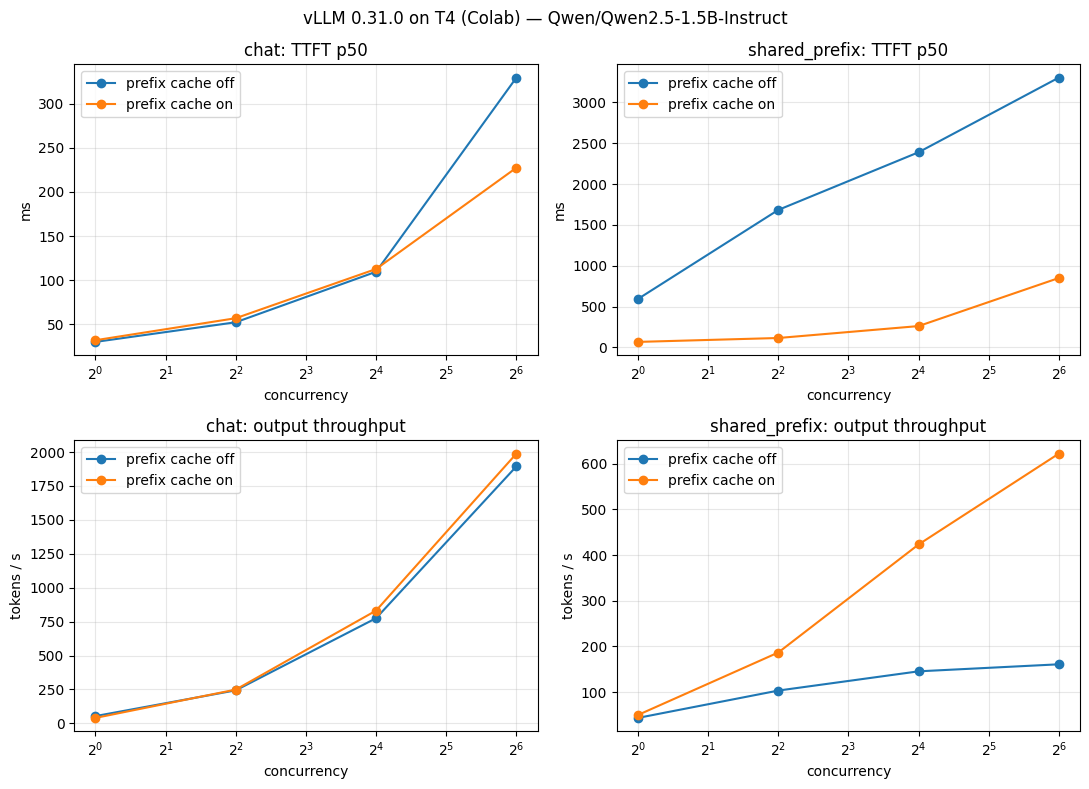

In [7]:
# 7. Table + plots
head = ("| Prefix cache | Workload | Concurrency | TTFT p50 (ms) | TTFT p99 (ms) | "
        "ITL p50 (ms) | ITL p99 (ms) | Output tok/s | Est. $ / 1M out tok |")
lines = [f"Model: {MODEL} | GPU: {GPU} | vLLM {VLLM_VERSION} | cost at ${REF_PRICE_PER_SEC}/s T4 list price\n",
         head, "|" + "---|" * 9]
for r in results["runs"]:
    lines.append(f"| {'on' if r['prefix_caching'] else 'off'} | {r['workload']} | {r['concurrency']} | "
                 f"{r['ttft_p50_ms']:.1f} | {r['ttft_p99_ms']:.1f} | {r['itl_p50_ms']:.1f} | "
                 f"{r['itl_p99_ms']:.1f} | {r['output_tok_s']:.0f} | ${r['est_usd_per_1m_out_tok']:.3f} |")
with open("results.md", "w") as f:
    f.write("\n".join(lines) + "\n")
print("\n".join(lines))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for col, wl in enumerate(("chat", "shared_prefix")):
    for pc in (False, True):
        rows = [r for r in results["runs"] if r["workload"] == wl and r["prefix_caching"] == pc]
        xs = [r["concurrency"] for r in rows]
        label = f"prefix cache {'on' if pc else 'off'}"
        axes[0, col].plot(xs, [r["ttft_p50_ms"] for r in rows], marker="o", label=label)
        axes[1, col].plot(xs, [r["output_tok_s"] for r in rows], marker="o", label=label)
    axes[0, col].set_title(f"{wl}: TTFT p50"); axes[0, col].set_ylabel("ms")
    axes[1, col].set_title(f"{wl}: output throughput"); axes[1, col].set_ylabel("tokens / s")
    for ax in axes[:, col]:
        ax.set_xscale("log", base=2); ax.set_xlabel("concurrency"); ax.legend(); ax.grid(alpha=0.3)
fig.suptitle(f"vLLM {VLLM_VERSION} on {GPU} — {MODEL}")
fig.tight_layout()
fig.savefig("results.png", dpi=150)
plt.show()

In [10]:
# 8. Download results
from google.colab import files
for f in ("results.json", "results.md", "results.png"):
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>